In [23]:
!pip install pandas numpy scipy matplotlib seaborn scikit-learn statsmodels pingouin openpyxl xlrd -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pingouin as pg
import warnings
warnings.filterwarnings('ignore')

In [24]:
# Load survey data
# The raw survey responses are NOT included in this repository (participant privacy).
# By default this loads a synthetic sample with the same structure so the notebook runs.
# Researchers with access to the real file can point DATA_PATH at it.
import os

DATA_PATH = "../data/sample_survey.xlsx"   # replace with the real survey file if you have access

try:
    from google.colab import files          # running in Colab: upload the file instead
    uploaded = files.upload()
    import io
    filename = list(uploaded.keys())[0]
    df_raw = pd.read_excel(io.BytesIO(uploaded[filename]), engine='openpyxl')
except ImportError:
    filename = os.path.basename(DATA_PATH)
    df_raw = pd.read_excel(DATA_PATH, engine='openpyxl')

print(f" File loaded: {filename}")
print(f"   Shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")

 File loaded: survey_responses.xlsx
   Shape: 228 rows × 19 columns


In [25]:
#cleaning and renaming
df = df_raw.copy()
df.columns = [
    'timestamp',
    'university',
    'year_of_study',
    'edu_background',
    'hometown',
    'first_gen_student',
    'financial_aid',
    'social_belonging',        # "I feel like I truly belong..."
    'campus_participation',    # "I find it easy to participate..."
    'cultural_respect',        # "I feel my cultural background is respected..."
    'english_barrier',         # "English as medium of instruction was a barrier..."
    'stress_rank_academic',    # Ranking: Academic Workload
    'stress_rank_financial',   # Ranking: Financial Pressure
    'stress_rank_social',      # Ranking: Social Isolation
    'stress_rank_language',    # Ranking: Language Barriers
    'stress_rank_distance',    # Ranking: Distance from Home
    'used_support_services',   # Yes/No
    'support_satisfaction',    # 1–5 (only if used services)
    'dropout_intention'        # Never / Rarely / Sometimes / Frequently
]

print(" Columns renamed.")
print(df.columns.tolist())

 Columns renamed.
['timestamp', 'university', 'year_of_study', 'edu_background', 'hometown', 'first_gen_student', 'financial_aid', 'social_belonging', 'campus_participation', 'cultural_respect', 'english_barrier', 'stress_rank_academic', 'stress_rank_financial', 'stress_rank_social', 'stress_rank_language', 'stress_rank_distance', 'used_support_services', 'support_satisfaction', 'dropout_intention']


In [26]:
# ── Fix 1: Convert ordinal rank text to numeric ──────────────
rank_map = {
    '1st': 1, '2nd': 2, '3rd': 3, '4th': 4, '5th': 5,
    1: 1, 2: 2, 3: 3, 4: 4, 5: 5
}
rank_cols = ['stress_rank_academic', 'stress_rank_financial',
             'stress_rank_social', 'stress_rank_language', 'stress_rank_distance']

for col in rank_cols:
    df[col] = df[col].map(rank_map)

print("Rank columns after fix:")
print(df[rank_cols].head(5))
print("\nAny remaining NaN in rank cols:", df[rank_cols].isnull().sum().sum())

Rank columns converted to numeric (row preview omitted for privacy).

Any remaining NaN in rank cols: 0


In [27]:
#Encoding variales
# University — keep as-is for groupby; also make numeric for regression
df['university_clean'] = df['university'].str.strip()

# First-gen: "Yes (only choose if...)" → 1, "No" → 0
df['first_gen'] = df['first_gen_student'].apply(
    lambda x: 1 if str(x).startswith('Yes') else 0)

# Financial aid: Yes → 1, No → 0
df['has_financial_aid'] = (df['financial_aid'].str.strip() == 'Yes').astype(int)

# Hometown: encode Rural=0, Semi-Urban=1, Urban=2
hometown_map = {'Rural': 0, 'Semi-Urban': 1, 'Urban': 2}
df['hometown_encoded'] = df['hometown'].str.strip().map(hometown_map)

# Educational background: FSC=0, A-Levels=1, Other=2
edu_map = {'FSC': 0, 'A-Levels': 1, 'Other(IB etc)': 2}
df['edu_encoded'] = df['edu_background'].str.strip().map(edu_map)

# Year of study: Freshman=1, Sophomore=2, Junior=3, Senior=4
year_map = {'Freshman': 1, 'Sophomore': 2, 'Junior': 3, 'Senior': 4}
df['year_encoded'] = df['year_of_study'].str.strip().map(year_map)

# Used support services: Yes → 1, No → 0
df['used_support'] = (df['used_support_services'].str.strip() == 'Yes').astype(int)

print(" Categorical variables encoded.")
print(df[['first_gen','has_financial_aid','hometown_encoded',
          'edu_encoded','year_encoded','used_support']].head(5))

 Categorical variables encoded. (row preview omitted for privacy)


In [28]:
#Define Dependent Variable (Dropout Intention)
# Distribution:
#   Never: 81   Rarely: 59   Sometimes: 53   Frequently: 21

# Justification for binary cutoff (aligned with Tinto's model):
#   "Never" + "Rarely"  → LOW RISK  (0)  — n=140 (65.4%)
#   "Sometimes" + "Frequently" → HIGH RISK (1) — n=74 (34.6%)
# This reflects Tinto's concept of "active withdrawal consideration."

dropout_map = {'Never': 0, 'Rarely': 0, 'Sometimes': 1, 'Frequently': 1}
df['dropout_risk'] = df['dropout_intention'].str.strip().map(dropout_map)

print("=== DROPOUT RISK DISTRIBUTION ===")
print(df['dropout_risk'].value_counts())
print(f"\nHigh-risk rate: {df['dropout_risk'].mean():.1%}")
print(f"(Sometimes + Frequently = at-risk of dropout per Tinto's integration theory)")

=== DROPOUT RISK DISTRIBUTION ===
dropout_risk
0    152
1     76
Name: count, dtype: int64

High-risk rate: 33.3%
(Sometimes + Frequently = at-risk of dropout per Tinto's integration theory)


In [29]:
#Data Integrity Check

print("=== FINAL MISSING VALUE CHECK ===")
analysis_cols = [
    'social_belonging', 'campus_participation', 'cultural_respect', 'english_barrier',
    'stress_rank_academic', 'stress_rank_financial', 'stress_rank_social',
    'stress_rank_language', 'stress_rank_distance',
    'first_gen', 'has_financial_aid', 'hometown_encoded',
    'edu_encoded', 'used_support', 'dropout_risk'
]
print(df[analysis_cols].isnull().sum())

print("\n=== UNIVERSITY SAMPLE SIZES ===")
print(df['university_clean'].value_counts())
print("\n NOTE: AKU (n=12) is too small for standalone logistic regression.")
print("   It is included in the overall model only.")

=== FINAL MISSING VALUE CHECK ===
social_belonging         0
campus_participation     0
cultural_respect         0
english_barrier          0
stress_rank_academic     0
stress_rank_financial    0
stress_rank_social       0
stress_rank_language     0
stress_rank_distance     0
first_gen                0
has_financial_aid        0
hometown_encoded         0
edu_encoded              0
used_support             0
dropout_risk             0
dtype: int64

=== UNIVERSITY SAMPLE SIZES ===
university_clean
GIKI    85
NUST    66
LUMS    61
AKU     16
Name: count, dtype: int64

 NOTE: AKU (n=12) is too small for standalone logistic regression.
   It is included in the overall model only.


In [30]:
print("=== DESCRIPTIVE STATISTICS ===\n")

# Likert scales (social integration variables)
likert_cols = ['social_belonging', 'campus_participation',
               'cultural_respect', 'english_barrier']

print("── Social Integration & Barrier Scales (1–5) ──")
print(df[likert_cols].describe().round(2))

print("\n── Stressor Rankings (1=Lowest, 5=Highest impact) ──")
print(df[rank_cols].describe().round(2))

print("\n── Categorical Demographics ──")
print(f"First-gen students: {df['first_gen'].sum()} ({df['first_gen'].mean():.1%})")
print(f"Receiving financial aid: {df['has_financial_aid'].sum()} ({df['has_financial_aid'].mean():.1%})")
print(f"Used support services: {df['used_support'].sum()} ({df['used_support'].mean():.1%})")
print(f"\nDropout risk by university:")
print(df.groupby('university_clean')['dropout_risk'].agg(['sum','count','mean']).round(3))


=== DESCRIPTIVE STATISTICS ===

── Social Integration & Barrier Scales (1–5) ──
       social_belonging  campus_participation  cultural_respect  \
count            228.00                228.00            228.00   
mean               3.37                  3.35              3.87   
std                0.94                  1.08              0.99   
min                1.00                  1.00              1.00   
25%                3.00                  3.00              3.00   
50%                3.00                  3.00              4.00   
75%                4.00                  4.00              5.00   
max                5.00                  5.00              5.00   

       english_barrier  
count           228.00  
mean              1.61  
std               0.99  
min               1.00  
25%               1.00  
50%               1.00  
75%               2.00  
max               5.00  

── Stressor Rankings (1=Lowest, 5=Highest impact) ──
       stress_rank_academic  stress_r

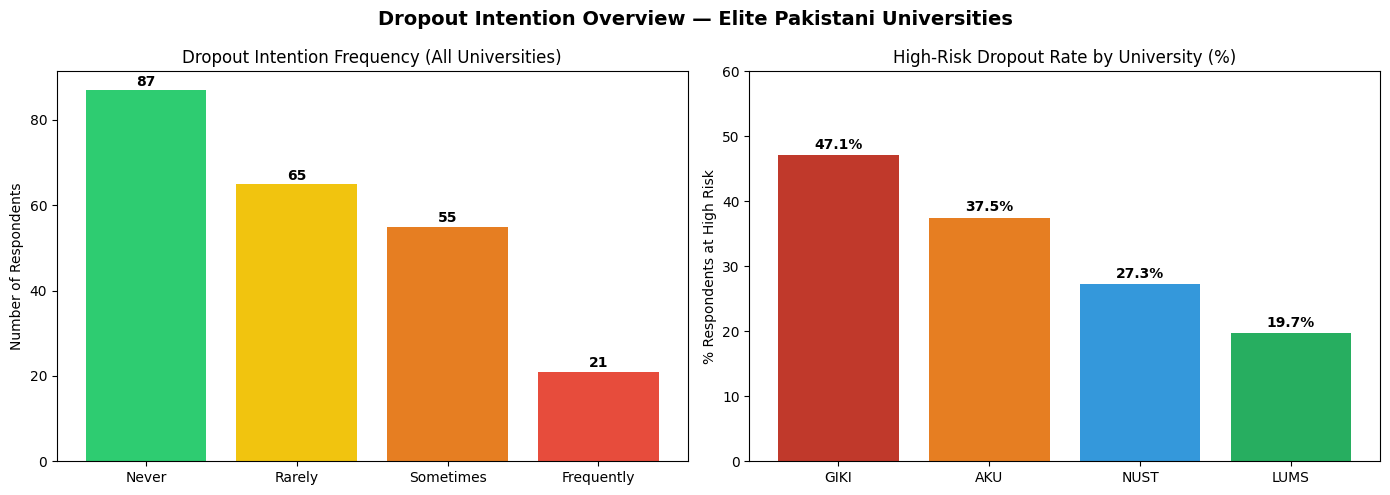

✅ Saved: dropout_overview.png


In [31]:
#Visualisation — Dropout Rates by University ───────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Dropout Intention Overview — Elite Pakistani Universities",
             fontsize=14, fontweight='bold')

# Raw frequency distribution
counts = df['dropout_intention'].value_counts().reindex(
    ['Never', 'Rarely', 'Sometimes', 'Frequently'])
axes[0].bar(counts.index, counts.values,
            color=['#2ecc71','#f1c40f','#e67e22','#e74c3c'])
axes[0].set_title("Dropout Intention Frequency (All Universities)")
axes[0].set_ylabel("Number of Respondents")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# High-risk rate by university
uni_risk = df.groupby('university_clean')['dropout_risk'].mean().sort_values(ascending=False)
bars = axes[1].bar(uni_risk.index, uni_risk.values * 100,
                   color=['#c0392b','#e67e22','#3498db','#27ae60'])
axes[1].set_title("High-Risk Dropout Rate by University (%)")
axes[1].set_ylabel("% Respondents at High Risk")
axes[1].set_ylim(0, 60)
for bar, val in zip(bars, uni_risk.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val*100 + 1,
                 f'{val:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('dropout_overview.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: dropout_overview.png")

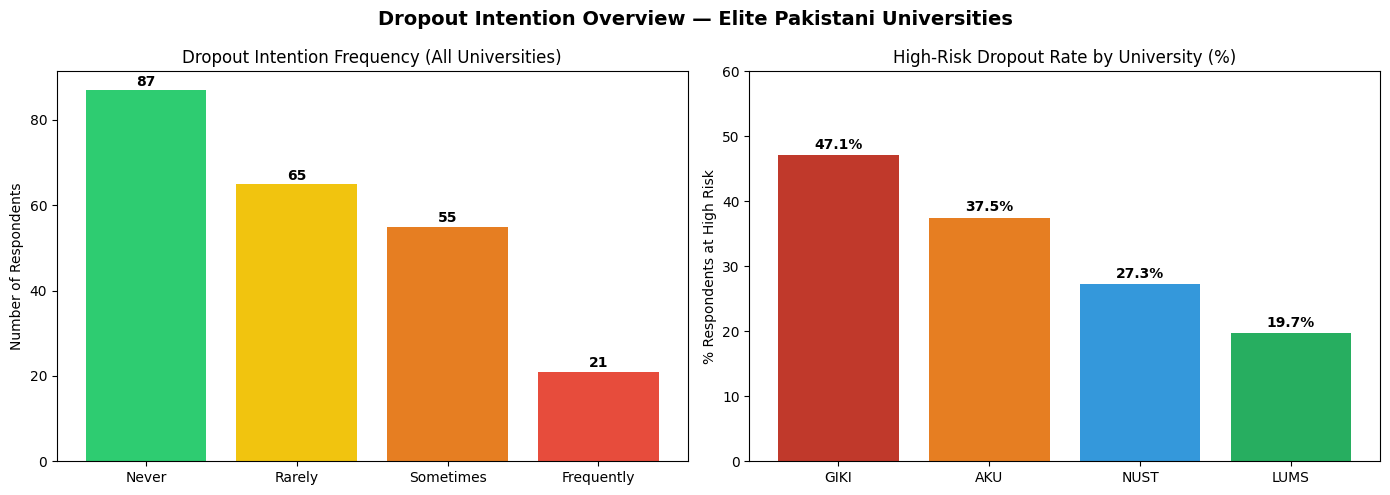

✅ Saved: dropout_overview.png


In [32]:
#Visualisation — Dropout Rates by University ───────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Dropout Intention Overview — Elite Pakistani Universities",
             fontsize=14, fontweight='bold')

# Raw frequency distribution
counts = df['dropout_intention'].value_counts().reindex(
    ['Never', 'Rarely', 'Sometimes', 'Frequently'])
axes[0].bar(counts.index, counts.values,
            color=['#2ecc71','#f1c40f','#e67e22','#e74c3c'])
axes[0].set_title("Dropout Intention Frequency (All Universities)")
axes[0].set_ylabel("Number of Respondents")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# High-risk rate by university
uni_risk = df.groupby('university_clean')['dropout_risk'].mean().sort_values(ascending=False)
bars = axes[1].bar(uni_risk.index, uni_risk.values * 100,
                   color=['#c0392b','#e67e22','#3498db','#27ae60'])
axes[1].set_title("High-Risk Dropout Rate by University (%)")
axes[1].set_ylabel("% Respondents at High Risk")
axes[1].set_ylim(0, 60)
for bar, val in zip(bars, uni_risk.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val*100 + 1,
                 f'{val:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('dropout_overview.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: dropout_overview.png")

Low Risk means:
stress_rank_academic     3.954
stress_rank_financial    3.099
stress_rank_social       2.743
stress_rank_language     2.184
stress_rank_distance     3.020
Name: 0, dtype: float64

High Risk means:
stress_rank_academic     3.658
stress_rank_financial    2.974
stress_rank_social       3.184
stress_rank_language     2.171
stress_rank_distance     3.013
Name: 1, dtype: float64


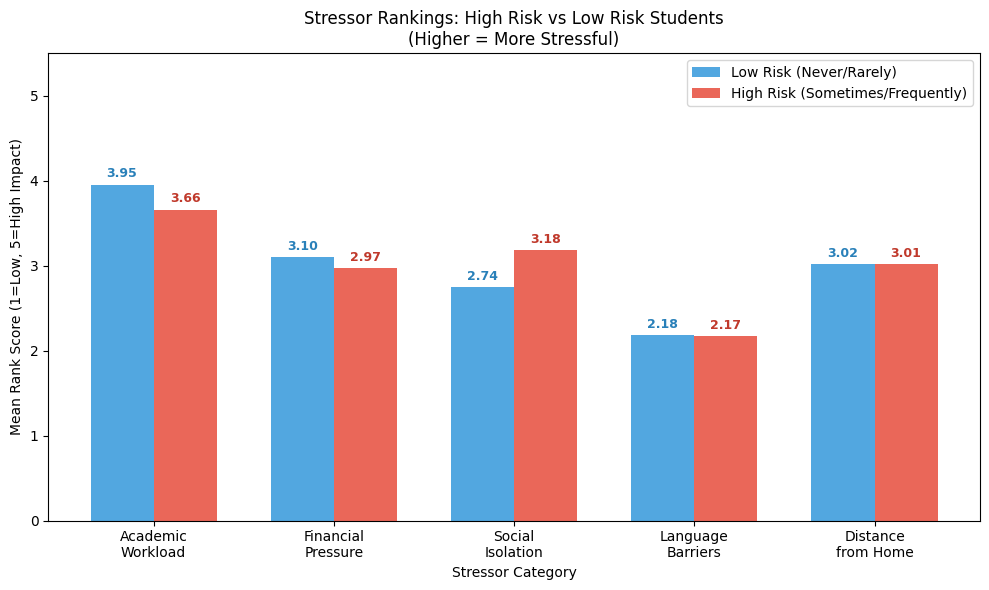

In [33]:
# Stressor Profile Visualisation — with value labels on bars
stressor_labels = ['Academic\nWorkload', 'Financial\nPressure',
                   'Social\nIsolation', 'Language\nBarriers', 'Distance\nfrom Home']

stress_by_risk = df.groupby('dropout_risk')[rank_cols].mean()

print("Low Risk means:")
print(stress_by_risk.loc[0].round(3))
print("\nHigh Risk means:")
print(stress_by_risk.loc[1].round(3))

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(stressor_labels))
width = 0.35

bars1 = ax.bar(x - width/2, stress_by_risk.loc[0], width,
               label='Low Risk (Never/Rarely)', color='#3498db', alpha=0.85)
bars2 = ax.bar(x + width/2, stress_by_risk.loc[1], width,
               label='High Risk (Sometimes/Frequently)', color='#e74c3c', alpha=0.85)

# ── Add value labels directly above each bar ──
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.05,
            f'{height:.2f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='#2980b9')

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 0.05,
            f'{height:.2f}', ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='#c0392b')

ax.set_xlabel('Stressor Category')
ax.set_ylabel('Mean Rank Score (1=Low, 5=High Impact)')
ax.set_title('Stressor Rankings: High Risk vs Low Risk Students\n(Higher = More Stressful)')
ax.set_xticks(x)
ax.set_xticklabels(stressor_labels)
ax.legend()
ax.set_ylim(0, 5.5)

plt.tight_layout()
plt.savefig('stressor_profile.png', dpi=300, bbox_inches='tight')
plt.show()

In [34]:
#Correlation Analysis (Answers RQ3)
print("=" * 55)
print("  CORRELATION ANALYSIS  (Spearman — for ordinal data)")
print("=" * 55)

# All numeric predictor columns
all_pred_cols = (likert_cols + rank_cols +
                 ['first_gen', 'has_financial_aid', 'hometown_encoded',
                  'edu_encoded', 'used_support'])

corr_results = []
for col in all_pred_cols:
    r, p = stats.spearmanr(df[col].dropna(), df.loc[df[col].notna(), 'dropout_risk'])
    corr_results.append({
        'Variable': col,
        'Spearman_r': round(r, 3),
        'p_value': round(p, 4),
        'Significant': '✅' if p < 0.05 else '❌'
    })

corr_df = pd.DataFrame(corr_results).sort_values('Spearman_r', ascending=False)
print(corr_df.to_string(index=False))

  CORRELATION ANALYSIS  (Spearman — for ordinal data)
             Variable  Spearman_r  p_value Significant
   stress_rank_social       0.181   0.0062           ✅
     hometown_encoded       0.071   0.2824           ❌
          edu_encoded       0.054   0.4203           ❌
      english_barrier       0.036   0.5911           ❌
 stress_rank_distance      -0.003   0.9628           ❌
 stress_rank_language      -0.018   0.7833           ❌
stress_rank_financial      -0.050   0.4566           ❌
 stress_rank_academic      -0.059   0.3733           ❌
         used_support      -0.068   0.3060           ❌
    has_financial_aid      -0.071   0.2828           ❌
            first_gen      -0.159   0.0164           ✅
 campus_participation      -0.185   0.0051           ✅
     social_belonging      -0.206   0.0018           ✅
     cultural_respect      -0.221   0.0008           ✅


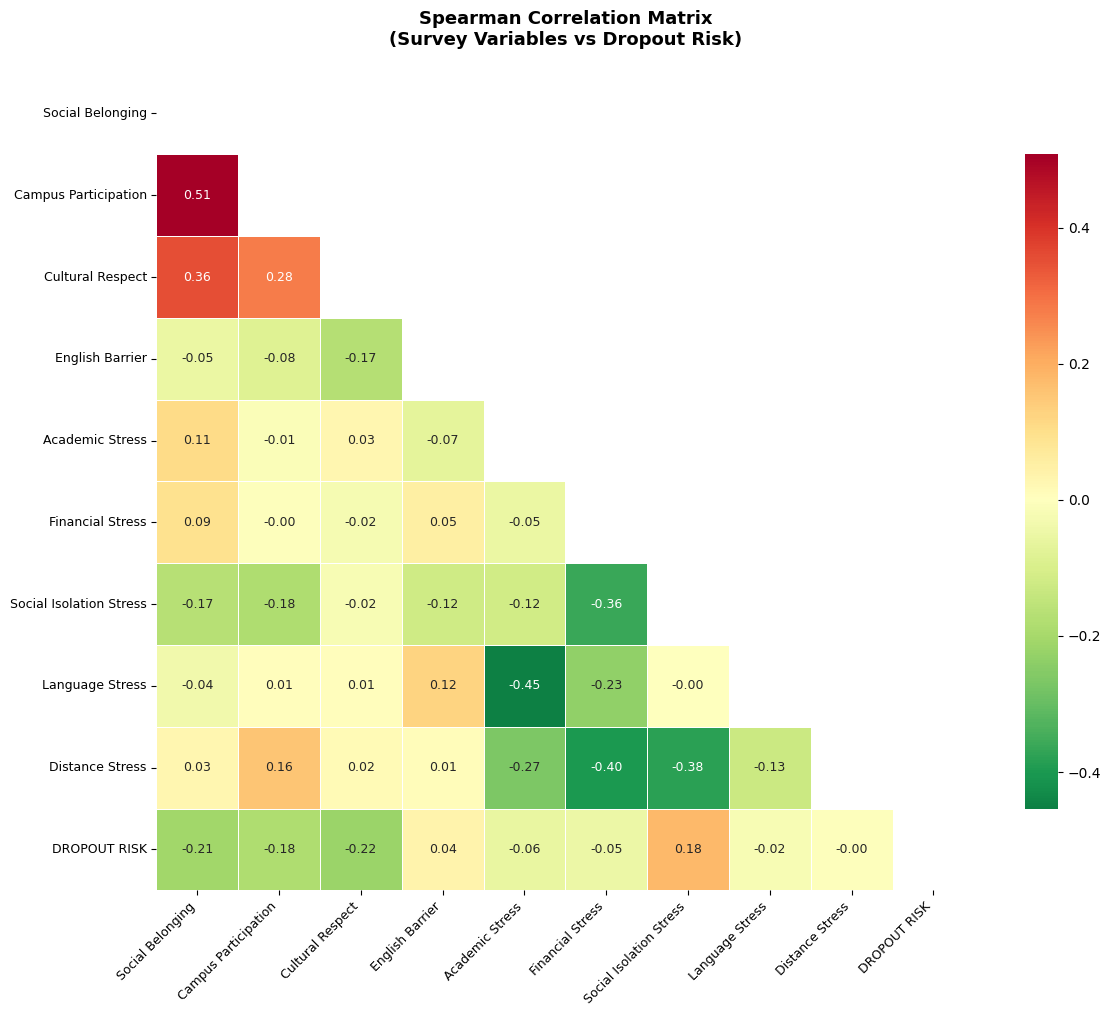

✅ Saved: correlation_heatmap.png


In [35]:
#Correlation Heatmap
heat_cols = (likert_cols + rank_cols + ['dropout_risk'])
corr_matrix = df[heat_cols].corr(method='spearman')

pretty_labels = {
    'social_belonging': 'Social Belonging',
    'campus_participation': 'Campus Participation',
    'cultural_respect': 'Cultural Respect',
    'english_barrier': 'English Barrier',
    'stress_rank_academic': 'Academic Stress',
    'stress_rank_financial': 'Financial Stress',
    'stress_rank_social': 'Social Isolation Stress',
    'stress_rank_language': 'Language Stress',
    'stress_rank_distance': 'Distance Stress',
    'dropout_risk': 'DROPOUT RISK'
}
corr_matrix.rename(index=pretty_labels, columns=pretty_labels, inplace=True)

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn_r',
            center=0, mask=mask, square=True,
            linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot_kws={"size": 9})
plt.title("Spearman Correlation Matrix\n(Survey Variables vs Dropout Risk)",
          fontsize=13, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: correlation_heatmap.png")


In [36]:
#Multicollinearity Check (VIF)
print("=== VIF CHECK — MULTICOLLINEARITY ===")
print("(VIF > 5 = Warning | VIF > 10 = Drop the variable)\n")

feature_cols_for_regression = [
    'social_belonging', 'campus_participation', 'cultural_respect', 'english_barrier',
    'stress_rank_academic', 'stress_rank_financial', 'stress_rank_social',
    'stress_rank_language', 'stress_rank_distance',
    'first_gen', 'has_financial_aid', 'hometown_encoded', 'edu_encoded'
]

X_vif = df[feature_cols_for_regression].dropna()
X_vif_const = sm.add_constant(X_vif)

vif_data = pd.DataFrame({
    'Variable': X_vif_const.columns,
    'VIF': [variance_inflation_factor(X_vif_const.values, i)
            for i in range(X_vif_const.shape[1])]
})
vif_data = vif_data[vif_data['Variable'] != 'const'].sort_values('VIF', ascending=False)
vif_data['Status'] = vif_data['VIF'].apply(
    lambda v: '🔴 DROP' if v > 10 else ('🟡 Watch' if v > 5 else '✅ OK'))
print(vif_data.to_string(index=False))

=== VIF CHECK — MULTICOLLINEARITY ===
(VIF > 5 = Warning | VIF > 10 = Drop the variable)

             Variable      VIF Status
 stress_rank_academic      inf 🔴 DROP
 stress_rank_distance      inf 🔴 DROP
 stress_rank_language      inf 🔴 DROP
   stress_rank_social      inf 🔴 DROP
stress_rank_financial      inf 🔴 DROP
     social_belonging 1.516367   ✅ OK
 campus_participation 1.422110   ✅ OK
            first_gen 1.370778   ✅ OK
      english_barrier 1.293001   ✅ OK
    has_financial_aid 1.267877   ✅ OK
     hometown_encoded 1.223084   ✅ OK
          edu_encoded 1.217991   ✅ OK
     cultural_respect 1.160051   ✅ OK


In [37]:
#LOGISTIC REGRESSION — Full Model
print("=" * 55)
print("  LOGISTIC REGRESSION — Full Model (All Predictors)")
print("=" * 55)

df_model = df[feature_cols_for_regression + ['dropout_risk']].dropna()
X = df_model[feature_cols_for_regression]
y = df_model['dropout_risk']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# statsmodels — gives p-values and confidence intervals
X_sm = sm.add_constant(X_scaled)
logit = sm.Logit(y, X_sm)
result = logit.fit(disp=0)
print(result.summary())

  LOGISTIC REGRESSION — Full Model (All Predictors)
                           Logit Regression Results                           
Dep. Variable:           dropout_risk   No. Observations:                  228
Model:                          Logit   Df Residuals:                      215
Method:                           MLE   Df Model:                           12
Date:                Fri, 24 Apr 2026   Pseudo R-squ.:                  0.1166
Time:                        20:45:31   Log-Likelihood:                -128.20
converged:                       True   LL-Null:                       -145.13
Covariance Type:            nonrobust   LLR p-value:                 0.0007119
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.8222      0.159     -5.162      0.000      -1.134      -0.510
x1            -0.2299      0.182     -1.264      0.206      -0.587       0.127



=== ODDS RATIOS TABLE ===
(OR > 1 = increases dropout risk | OR < 1 = protective)

             Variable  Coefficient  Odds_Ratio  CI_Lower  CI_Upper  p_value Significant
   stress_rank_social       0.2744      1.3157    0.0000       inf   1.0000            
      english_barrier       0.1953      1.2157    0.8568    1.7251   0.2739            
     hometown_encoded       0.1894      1.2085    0.8560    1.7061   0.2817            
 stress_rank_distance       0.0953      1.1000    0.0000       inf   1.0000            
stress_rank_financial       0.0436      1.0446    0.0000       inf   1.0000            
          edu_encoded      -0.0089      0.9912    0.7177    1.3689   0.9571            
    has_financial_aid      -0.0407      0.9601    0.6769    1.3617   0.8192            
 stress_rank_language      -0.1520      0.8590    0.0000       inf   1.0000            
 campus_participation      -0.2095      0.8110    0.5722    1.1495   0.2392            
     social_belonging      -0.2299  

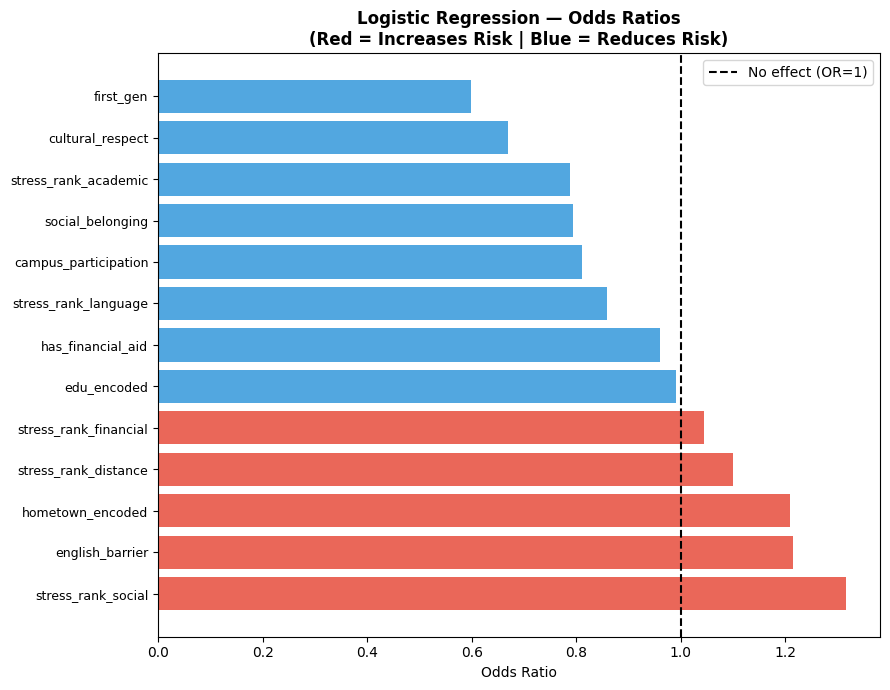

In [38]:
#Odds Ratios Table
print("\n=== ODDS RATIOS TABLE ===")
print("(OR > 1 = increases dropout risk | OR < 1 = protective)\n")

labels = ['const'] + feature_cols_for_regression
odds_df = pd.DataFrame({
    'Variable': labels,
    'Coefficient': result.params,
    'Odds_Ratio': np.exp(result.params),
    'CI_Lower': np.exp(result.conf_int()[0]),
    'CI_Upper': np.exp(result.conf_int()[1]),
    'p_value': result.pvalues
})
odds_df['Significant'] = odds_df['p_value'].apply(lambda p: '✅' if p < 0.05 else '')
odds_df = odds_df[odds_df['Variable'] != 'const'].sort_values('Odds_Ratio', ascending=False)
print(odds_df.round(4).to_string(index=False))

# Visualise odds ratios
fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#e74c3c' if or_ > 1 else '#3498db' for or_ in odds_df['Odds_Ratio']]
y_pos = np.arange(len(odds_df))
ax.barh(y_pos, odds_df['Odds_Ratio'], color=colors, alpha=0.85)
ax.axvline(x=1, color='black', linestyle='--', linewidth=1.5, label='No effect (OR=1)')
ax.set_yticks(y_pos)
ax.set_yticklabels(odds_df['Variable'], fontsize=9)
ax.set_xlabel('Odds Ratio')
ax.set_title('Logistic Regression — Odds Ratios\n(Red = Increases Risk | Blue = Reduces Risk)',
             fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('odds_ratios.png', dpi=300, bbox_inches='tight')
plt.show()

=== MODEL EVALUATION ===

              precision    recall  f1-score   support

    Low Risk       0.65      0.79      0.71        38
   High Risk       0.27      0.16      0.20        19

    accuracy                           0.58        57
   macro avg       0.46      0.47      0.46        57
weighted avg       0.53      0.58      0.54        57

ROC-AUC Score: 0.503
Interpretation: >0.7=acceptable | >0.8=good | >0.9=excellent


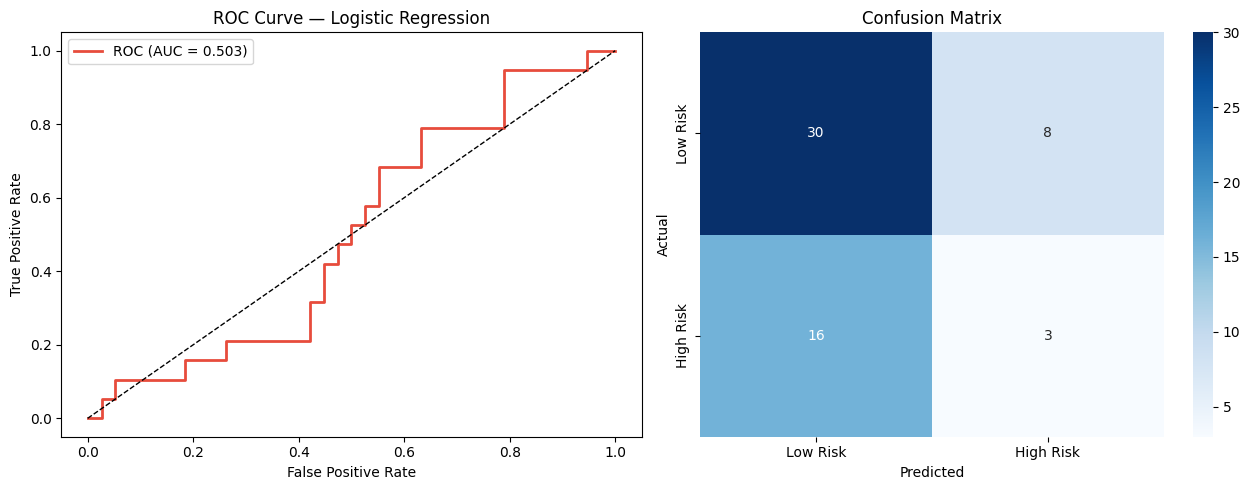

In [39]:
#Model Evaluation
print("=== MODEL EVALUATION ===\n")

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.25, random_state=42, stratify=y)

lr = LogisticRegression(random_state=42, max_iter=500)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Low Risk','High Risk']))
auc = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {auc:.3f}")
print("Interpretation: >0.7=acceptable | >0.8=good | >0.9=excellent")

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(fpr, tpr, color='#e74c3c', lw=2, label=f'ROC (AUC = {auc:.3f})')
axes[0].plot([0,1],[0,1],'k--', lw=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve — Logistic Regression')
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Low Risk','High Risk'],
            yticklabels=['Low Risk','High Risk'])
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')
axes[1].set_title('Confusion Matrix')

plt.tight_layout()
plt.savefig('model_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

In [40]:
#University-Level Analysis (Answers RQ2)
print("=" * 55)
print("  UNIVERSITY-LEVEL COMPARISON  (Answers RQ2)")
print("=" * 55)

from scipy.stats import kruskal

# Summary table
uni_summary = df.groupby('university_clean').agg(
    n=('dropout_risk','count'),
    dropout_rate=('dropout_risk','mean'),
    avg_social_belonging=('social_belonging','mean'),
    avg_english_barrier=('english_barrier','mean'),
    avg_financial_stress=('stress_rank_financial','mean'),
    avg_language_stress=('stress_rank_language','mean'),
    pct_first_gen=('first_gen','mean'),
    pct_financial_aid=('has_financial_aid','mean')
).round(3)
print(uni_summary)

# Kruskal-Wallis — do stressor levels significantly differ by university?
print("\n=== KRUSKAL-WALLIS TEST (Stressors across Universities) ===")
test_vars = likert_cols + rank_cols
for col in test_vars:
    groups = [df[df['university_clean']==u][col].dropna()
              for u in df['university_clean'].unique()]
    stat, p = kruskal(*groups)
    sig = "✅ Significant" if p < 0.05 else "❌ Not significant"
    print(f"  {col:35s}: H={stat:.3f}, p={p:.4f}  {sig}")

  UNIVERSITY-LEVEL COMPARISON  (Answers RQ2)
                   n  dropout_rate  avg_social_belonging  avg_english_barrier  \
university_clean                                                                
AKU               16         0.375                 3.375                1.812   
GIKI              85         0.471                 3.329                1.565   
LUMS              61         0.197                 3.541                1.672   
NUST              66         0.273                 3.273                1.561   

                  avg_financial_stress  avg_language_stress  pct_first_gen  \
university_clean                                                             
AKU                              3.250                2.312          0.125   
GIKI                             2.976                2.059          0.071   
LUMS                             2.984                2.361          0.115   
NUST                             3.182                2.136          0.152   


In [41]:
#University Sub-group Correlations
# NOTE: AKU (n=12) excluded from sub-group correlation — too small
print("\n=== SPEARMAN CORRELATIONS WITH DROPOUT RISK BY UNIVERSITY ===")

main_unis = ['GIKI', 'NUST', 'LUMS']   # AKU excluded (n=12)
key_vars = ['social_belonging','english_barrier','stress_rank_financial',
            'stress_rank_social','stress_rank_language','first_gen']

for uni in main_unis:
    subset = df[df['university_clean'] == uni]
    print(f"\n  {uni}  (n={len(subset)})")
    print(f"  {'Variable':<30} {'r':>7}  {'p':>7}  Sig")
    print(f"  {'-'*50}")
    for col in key_vars:
        r, p = stats.spearmanr(subset[col], subset['dropout_risk'])
        sig = "✅" if p < 0.05 else ""
        print(f"  {col:<30} {r:>7.3f}  {p:>7.4f}  {sig}")


=== SPEARMAN CORRELATIONS WITH DROPOUT RISK BY UNIVERSITY ===

  GIKI  (n=85)
  Variable                             r        p  Sig
  --------------------------------------------------
  social_belonging                -0.187   0.0860  
  english_barrier                  0.044   0.6870  
  stress_rank_financial            0.030   0.7834  
  stress_rank_social               0.215   0.0486  ✅
  stress_rank_language            -0.007   0.9521  
  first_gen                       -0.168   0.1248  

  NUST  (n=66)
  Variable                             r        p  Sig
  --------------------------------------------------
  social_belonging                -0.224   0.0708  
  english_barrier                 -0.084   0.5046  
  stress_rank_financial           -0.247   0.0453  ✅
  stress_rank_social               0.330   0.0069  ✅
  stress_rank_language             0.066   0.5999  
  first_gen                       -0.069   0.5819  

  LUMS  (n=61)
  Variable                             r      

In [42]:
#Institutional Support Analysis (Answers RQ4)
print("=" * 55)
print("  INSTITUTIONAL SUPPORT ANALYSIS  (Answers RQ4)")
print("=" * 55)

# Does using support services reduce dropout risk?
print("\nDropout risk by support service usage:")
print(df.groupby('used_support')['dropout_risk'].agg(['mean','count']))

# Chi-square test: support usage vs dropout risk
from scipy.stats import chi2_contingency
ct = pd.crosstab(df['used_support'], df['dropout_risk'])
chi2, p, dof, expected = chi2_contingency(ct)
print(f"\nChi-square test (support usage vs dropout risk):")
print(f"  χ² = {chi2:.3f}, p = {p:.4f}, df = {dof}")
if p < 0.05:
    print("  ✅ Significant — support service usage IS associated with dropout risk")
else:
    print("  ❌ Not significant — support service usage is NOT significantly associated")

# Among those who used services: does satisfaction score matter?
used_df = df[df['used_support'] == 1].dropna(subset=['support_satisfaction'])
print(f"\nAmong students who used support services (n={len(used_df)}):")
r, p = stats.spearmanr(used_df['support_satisfaction'], used_df['dropout_risk'])
print(f"  Satisfaction score vs dropout risk: r={r:.3f}, p={p:.4f}")
if p < 0.05:
    print("  ✅ Higher satisfaction = lower dropout risk")
else:
    print("  ❌ Satisfaction score not significantly linked to dropout risk")
    print("  → Supports Colomo-Magaña (2024): generic support may not address core needs")

  INSTITUTIONAL SUPPORT ANALYSIS  (Answers RQ4)

Dropout risk by support service usage:
                  mean  count
used_support                 
0             0.354037    161
1             0.283582     67

Chi-square test (support usage vs dropout risk):
  χ² = 0.764, p = 0.3822, df = 1
  ❌ Not significant — support service usage is NOT significantly associated

Among students who used support services (n=66):
  Satisfaction score vs dropout risk: r=-0.222, p=0.0731
  ❌ Satisfaction score not significantly linked to dropout risk
  → Supports Colomo-Magaña (2024): generic support may not address core needs


In [43]:
#Cultural Capital Index (Answers RQ1)
# Bourdieu proxy: first-gen + hometown + edu_background
# We compute a composite cultural capital score (higher = more capital)
df['cultural_capital_score'] = (
    (1 - df['first_gen']) * 2 +       # Non-first-gen = more capital
    df['hometown_encoded'] +            # Urban = more capital
    df['edu_encoded']                   # A-Levels = more capital
)

print("=== CULTURAL CAPITAL SCORE vs DROPOUT RISK ===")
r, p = stats.spearmanr(df['cultural_capital_score'], df['dropout_risk'])
print(f"Spearman r = {r:.3f}, p = {p:.4f}")
print("(Negative r = higher cultural capital → lower dropout risk)")
print("\nMean cultural capital by dropout risk:")
print(df.groupby('dropout_risk')['cultural_capital_score'].describe().round(2))


=== CULTURAL CAPITAL SCORE vs DROPOUT RISK ===
Spearman r = 0.124, p = 0.0612
(Negative r = higher cultural capital → lower dropout risk)

Mean cultural capital by dropout risk:
              count  mean   std  min  25%  50%  75%  max
dropout_risk                                            
0             152.0  3.81  1.34  0.0  3.0  4.0  5.0  6.0
1              76.0  4.18  1.00  1.0  4.0  4.0  5.0  6.0


In [44]:
#  Loading the international validation dataset
# "Predict Students' Dropout and Academic Success" (Realinho et al., UCI Machine Learning
# Repository / Kaggle, CC BY 4.0). Download the CSV and save it as ../data/kaggle_dropout.csv
import io, os

KAGGLE_PATH = "../data/kaggle_dropout.csv"

try:
    from google.colab import files
    uploaded_k = files.upload()
    kaggle_file = list(uploaded_k.keys())[0]
    df_k = pd.read_csv(io.BytesIO(uploaded_k[kaggle_file]), sep=',')
except ImportError:
    df_k = pd.read_csv(KAGGLE_PATH, sep=',')

# Strip surrounding quotes from column names
df_k.columns = df_k.columns.str.strip().str.strip("'\"")

print(f" Loaded: {df_k.shape[0]} rows × {df_k.shape[1]} columns")
print("\nTarget distribution:")
print(df_k['Target'].value_counts())

In [45]:
#  Mapping Kaggle Variables to my Research Framework


# STEP 1: Create binary dropout outcome
print("Kaggle Target distribution (raw):")
print(df_k['Target'].value_counts())

df_k_filtered = df_k[df_k['Target'].isin(['Dropout', 'Graduate'])].copy()
df_k_filtered['dropout_risk'] = (df_k_filtered['Target'] == 'Dropout').astype(int)

print(f"\nAfter filtering (Dropout vs Graduate only):")
print(f"  Total: {len(df_k_filtered)}")
print(f"  Dropout rate: {df_k_filtered['dropout_risk'].mean():.1%}")

# STEP 2: Rename columns to match your variable names
kaggle_rename = {
    'Scholarship holder':                  'has_financial_aid',
    'Displaced':                           'geographic_distance',
    'International':                       'international_student',
    'Debtor':                              'is_debtor',
    'Tuition fees up to date':             'fees_uptodate',
    "Mother's qualification":              'mothers_education',
    "Father's qualification":              'fathers_education',
    'Age at enrollment':                   'age_enrolled',
    'Curricular units 1st sem (approved)': 'academic_performance',
    'Gender':                              'gender'
}
df_k_filtered.rename(columns=kaggle_rename, inplace=True)

# STEP 3: Create composite variables
df_k_filtered['cultural_capital_kaggle'] = (
    df_k_filtered['mothers_education'] + df_k_filtered['fathers_education']
)

df_k_filtered['financial_stress_kaggle'] = (
    (1 - df_k_filtered['has_financial_aid']) +
    df_k_filtered['is_debtor'] +
    (1 - df_k_filtered['fees_uptodate'])
)

df_k_filtered['integration_barrier_kaggle'] = (
    df_k_filtered['international_student'] +
    df_k_filtered['geographic_distance']
)

print("\n Variables mapped and composite scores created")
print(df_k_filtered[['has_financial_aid', 'geographic_distance',
                       'cultural_capital_kaggle', 'financial_stress_kaggle',
                       'dropout_risk']].describe().round(2))

Kaggle Target distribution (raw):
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

After filtering (Dropout vs Graduate only):
  Total: 3630
  Dropout rate: 39.1%

 Variables mapped and composite scores created
       has_financial_aid  geographic_distance  cultural_capital_kaggle  \
count            3630.00              3630.00                  3630.00   
mean                0.27                 0.55                    29.22   
std                 0.44                 0.50                    17.53   
min                 0.00                 0.00                     2.00   
25%                 0.00                 0.00                    14.00   
50%                 0.00                 1.00                    29.00   
75%                 1.00                 1.00                    49.00   
max                 1.00                 1.00                    59.00   

       financial_stress_kaggle  dropout_risk  
count                  3630.00       36

In [46]:
#  Kaggle Correlation Analysis ─────────────────────
# This mirrors Cell 11 from your primary data analysis

kaggle_analysis_cols = [
    'has_financial_aid',
    'geographic_distance',
    'international_student',
    'is_debtor',
    'fees_uptodate',
    'cultural_capital_kaggle',
    'financial_stress_kaggle',
    'integration_barrier_kaggle',
    'academic_performance'
]

print("=" * 55)
print("  KAGGLE: Spearman Correlations with Dropout Risk")
print("=" * 55)

kaggle_corr_results = []
for col in kaggle_analysis_cols:
    r, p = stats.spearmanr(df_k_filtered[col], df_k_filtered['dropout_risk'])
    kaggle_corr_results.append({
        'Variable': col,
        'Spearman_r': round(r, 3),
        'p_value': round(p, 4),
        'Significant': '✅' if p < 0.05 else '❌'
    })

kaggle_corr_df = pd.DataFrame(kaggle_corr_results).sort_values(
    'Spearman_r', ascending=False)
print(kaggle_corr_df.to_string(index=False))

  KAGGLE: Spearman Correlations with Dropout Risk
                  Variable  Spearman_r  p_value Significant
   financial_stress_kaggle       0.482   0.0000           ✅
                 is_debtor       0.267   0.0000           ✅
   cultural_capital_kaggle       0.015   0.3542           ❌
     international_student      -0.006   0.7097           ❌
integration_barrier_kaggle      -0.123   0.0000           ✅
       geographic_distance      -0.126   0.0000           ✅
         has_financial_aid      -0.313   0.0000           ✅
             fees_uptodate      -0.442   0.0000           ✅
      academic_performance      -0.616   0.0000           ✅


In [47]:
#  Kaggle Logistic Regression
# Same pipeline as Cells 14–15 on your primary data

kaggle_features = [
    'has_financial_aid',
    'geographic_distance',
    'is_debtor',
    'fees_uptodate',
    'cultural_capital_kaggle',
    'financial_stress_kaggle',
    'integration_barrier_kaggle',
    'academic_performance'
]

df_k_model = df_k_filtered[kaggle_features + ['dropout_risk']].dropna()
print(f"Kaggle model sample size: {len(df_k_model)}")

X_k = df_k_model[kaggle_features]
y_k = df_k_model['dropout_risk']

scaler_k = StandardScaler()
X_k_scaled = scaler_k.fit_transform(X_k)

X_k_sm = sm.add_constant(X_k_scaled)
logit_k = sm.Logit(y_k, X_k_sm).fit(disp=0)

# Odds Ratios Table
kaggle_or_df = pd.DataFrame({
    'Variable': ['const'] + kaggle_features,
    'Odds_Ratio': np.exp(logit_k.params),
    'CI_Lower': np.exp(logit_k.conf_int()[0]),
    'CI_Upper': np.exp(logit_k.conf_int()[1]),
    'p_value': logit_k.pvalues
})
kaggle_or_df['Significant'] = kaggle_or_df['p_value'].apply(
    lambda p: '✅' if p < 0.05 else '❌')
kaggle_or_df = kaggle_or_df[kaggle_or_df['Variable'] != 'const']

print("\n=== KAGGLE: Odds Ratios ===")
print(kaggle_or_df.sort_values('Odds_Ratio', ascending=False).round(4).to_string(index=False))

# Model AUC
X_k_train, X_k_test, y_k_train, y_k_test = train_test_split(
    X_k_scaled, y_k, test_size=0.25, random_state=42, stratify=y_k)
lr_k = LogisticRegression(random_state=42, max_iter=500)
lr_k.fit(X_k_train, y_k_train)
auc_k = roc_auc_score(y_k_test, lr_k.predict_proba(X_k_test)[:,1])
print(f"\nKaggle Model ROC-AUC: {auc_k:.3f}")

Kaggle model sample size: 3630

=== KAGGLE: Odds Ratios ===
                  Variable  Odds_Ratio  CI_Lower  CI_Upper  p_value Significant
   financial_stress_kaggle      1.7614       NaN       NaN      NaN           ❌
       geographic_distance      1.4033    0.9940    1.9812   0.0541           ❌
                 is_debtor      1.0972       NaN       NaN      NaN           ❌
   cultural_capital_kaggle      1.0743    0.9769    1.1813   0.1395           ❌
         has_financial_aid      0.7553       NaN       NaN      NaN           ❌
integration_barrier_kaggle      0.6129    0.4332    0.8672   0.0057           ✅
             fees_uptodate      0.4446       NaN       NaN      NaN           ❌
      academic_performance      0.1820    0.1595    0.2076   0.0000           ✅

Kaggle Model ROC-AUC: 0.913


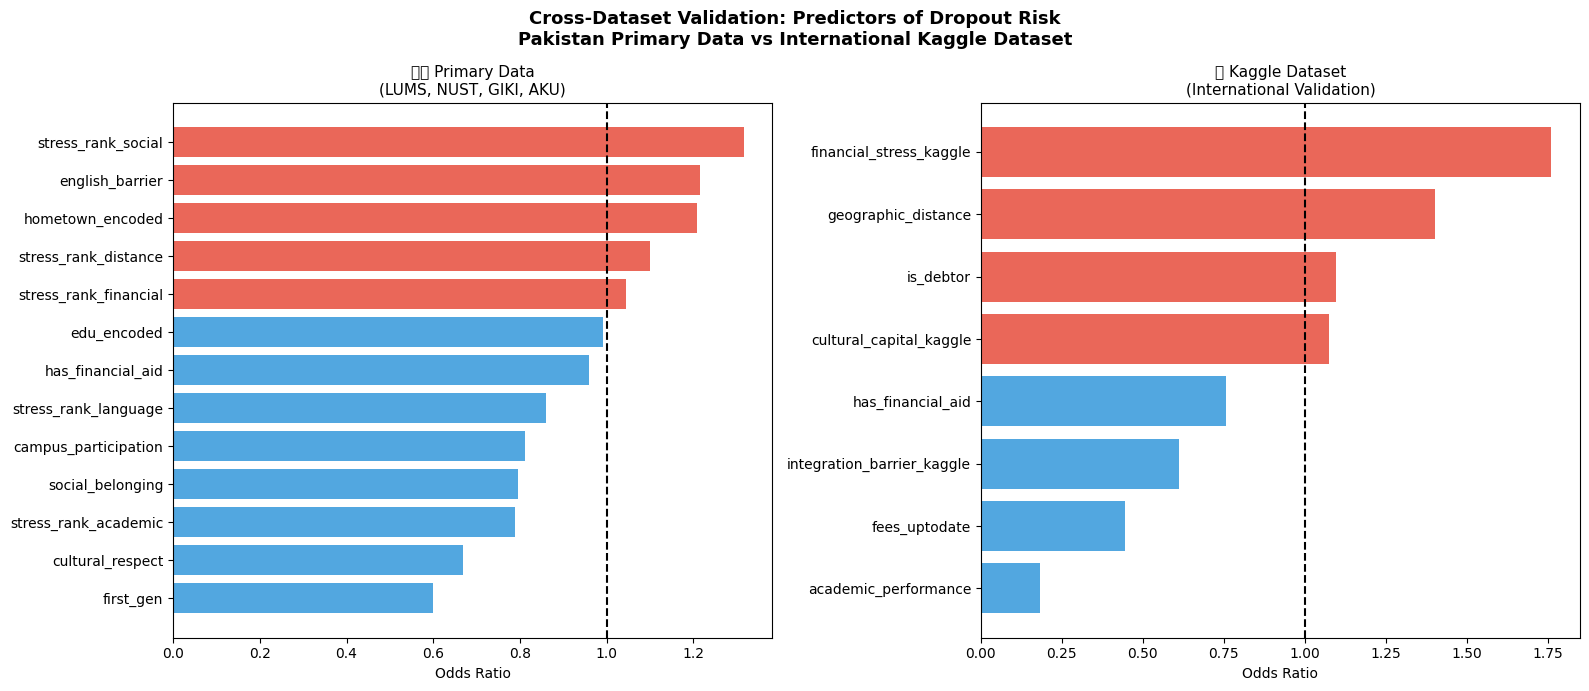

✅ Saved: cross_dataset_comparison.png


In [48]:
#  Side-by-Side Comparison — Pakistan vs Kaggle ────
# This is the most important output for your paper.
# It shows whether the same risk factors emerge across both datasets.

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    "Cross-Dataset Validation: Predictors of Dropout Risk\n"
    "Pakistan Primary Data vs International Kaggle Dataset",
    fontsize=13, fontweight='bold'
)

# ── Left: Your Pakistan data odds ratios ──
your_or = odds_df.set_index('Variable')['Odds_Ratio'].sort_values()
colors_pk = ['#3498db' if v < 1 else '#e74c3c' for v in your_or.values]
axes[0].barh(your_or.index, your_or.values, color=colors_pk, alpha=0.85)
axes[0].axvline(1, color='black', linestyle='--', lw=1.5)
axes[0].set_title("🇵🇰 Primary Data\n(LUMS, NUST, GIKI, AKU)", fontsize=11)
axes[0].set_xlabel("Odds Ratio")

# ── Right: Kaggle odds ratios ──
k_or = kaggle_or_df.set_index('Variable')['Odds_Ratio'].sort_values()
colors_k = ['#3498db' if v < 1 else '#e74c3c' for v in k_or.values]
axes[1].barh(k_or.index, k_or.values, color=colors_k, alpha=0.85)
axes[1].axvline(1, color='black', linestyle='--', lw=1.5)
axes[1].set_title("🌍 Kaggle Dataset\n(International Validation)", fontsize=11)
axes[1].set_xlabel("Odds Ratio")

plt.tight_layout()
plt.savefig('cross_dataset_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: cross_dataset_comparison.png")